# Imports + load csv and checkpoint

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance
from sklearn.neighbors import NearestNeighbors
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
import warnings
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, rand_score, adjusted_rand_score
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
import os
import pickle
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn import metrics
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
import pickle

In [3]:
df = pd.read_csv('./ddos_dataset_pre_PCA.csv', dtype={'SimillarHTTP':str}, index_col=0)

In [4]:
with open("./dbscan_checkpoint.pkl", "rb") as f:
            results = pickle.load(f)

# Calculation

In [5]:
df.columns = df.columns.str.strip()

Y = df['label'].values #Feature Label

columns_to_drop_for_DBSCAN = [
    'Timestamp',
    'label',
    'Source IP',
    'Destination IP',
    'Source Port',
    'Destination Port',
    'Flow ID',
    ]

df = df.drop(columns=columns_to_drop_for_DBSCAN, errors='ignore')

X = df.to_numpy() #X From clean dataframe

print("Colonne rimaste:", df.columns.tolist()) #Check if effectively dropped
print("Shape di X:", X.shape)
print("Tipi di dato:", df.dtypes.unique())

# With DBSCAN we can use Euclidean distance, so we need to standardize the features: In this way all features will contribute equally to the distance computations.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Verification of the standardization

print("Standardized data shape:", X_scaled.shape)
print("max |mean|:", np.max(np.abs(X_scaled.mean(axis=0)))) # Should be 0 (or in a range as [0, 1e-12]) if normalized correctly
print("max |std-1|:", np.max(np.abs(X_scaled.std(axis=0)-1))) # Should be 1 if normalized correctly

Colonne rimaste: ['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'SYN Flag Count', 'RST Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Subf

In [6]:
def dbscan_tuning(checkpoint_file, eps_range, min_samples_range, df, df_labels):
    if os.path.exists(checkpoint_file):
        with open(checkpoint_file, "rb") as f:
            db_results = pickle.load(f)
        print("Resume from existing checkpoint.")
    else:
        db_results = {
            "eps": [], "min_samples": [],
            "silhouette": [], "RI": [], "ARI": [],
            "n_clusters": [], "noise_ratio": [],
            "cluster_labels":[]
        }

    for eps in eps_range:
        eps = round(eps, 3)
        for mins in min_samples_range:
            # Skip if already done
            if any(np.isclose(db_results["eps"], eps) & (np.array(db_results["min_samples"]) == mins)):
                continue

            print(f"Testing eps={eps}, min_samples={mins}...")
            db = DBSCAN(eps=eps, min_samples=mins, algorithm='ball_tree',n_jobs=-1).fit(df)
            labels = db.labels_
            print(f"DBSCAN done. Calculating metrics...")
            # Metrics
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            noise_ratio = np.sum(labels == -1) / len(labels)

            # Silhouette requires at least 2 clusters
            if 1 < n_clusters < len(df):
                # We use a good number of samples and not the entire dataset because calculation would be too long
                sil = metrics.silhouette_score(df, labels)
            else:
                sil = -1.0

            ri = metrics.rand_score(df_labels, labels)
            ari = metrics.adjusted_rand_score(df_labels, labels)

            print(f"\tMetrics: \n\tn_clusters: {n_clusters}\n\tnoise_ratio: {noise_ratio}\n\tsilhouette: {sil}\n\tri: {ri}\n\tari: {ari}")

            # Save results
            db_results["eps"].append(eps)
            db_results["min_samples"].append(mins)
            db_results["silhouette"].append(sil)
            db_results["RI"].append(ri)
            db_results["ARI"].append(ari)
            db_results["n_clusters"].append(n_clusters)
            db_results["noise_ratio"].append(noise_ratio)
            db_results["cluster_labels"].append(labels)

            with open(checkpoint_file, "wb") as f:
                pickle.dump(db_results, f)

    print("DBSCAN Tuning terminated.")
    return db_results

In [7]:
# Define values based on the elbow plot (Phase 1)
eps_values = [0.1,0.3,0.5, 0.67, 0.8,1,1.1,1.2,1.3,1.4,1.5,2,2.5,3,5,7]
min_samples_values = [1,2,3,5,8,10,20,30,40,50,60,70,80,90,100,110,120,200,500,800,1000,2000]

# Run tuning
results = dbscan_tuning("dbscan_checkpoint.pkl", eps_values, min_samples_values, X_scaled, Y)

Resume from existing checkpoint.
DBSCAN Tuning terminated.


# PLOT

## METRICS

In [8]:
def plot_dbscan_metrics(db_results):
    df_res = pd.DataFrame(db_results)
    
    # Preparing the figure
    fig, axs = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle("DBSCAN Performance Analysis - Grid Search Results")

    metrics_to_plot = [
        ('silhouette', 'Silhouette Score', 'viridis'),
        ('ARI', 'Adjusted Rand Index', 'plasma'),
        ('n_clusters', 'Number of Clusters', 'magma'),
        ('noise_ratio', 'Noise Ratio (Ratio of -1)', 'coolwarm')
    ]

    for i, (col, title, cmap) in enumerate(metrics_to_plot):
        ax = axs[i//2, i%2]
        pivot = df_res.pivot_table(index='min_samples', columns='eps', values=col)
        
        sns.heatmap(pivot, annot=True, fmt=".2f" if i != 2 else ".0f", 
                    cmap=cmap, ax=ax, cbar_kws={'label': col})
        
        ax.set_title(title)
        ax.invert_yaxis() # To have min_samples increasing towards top

    plt.tight_layout()
    plt.show()

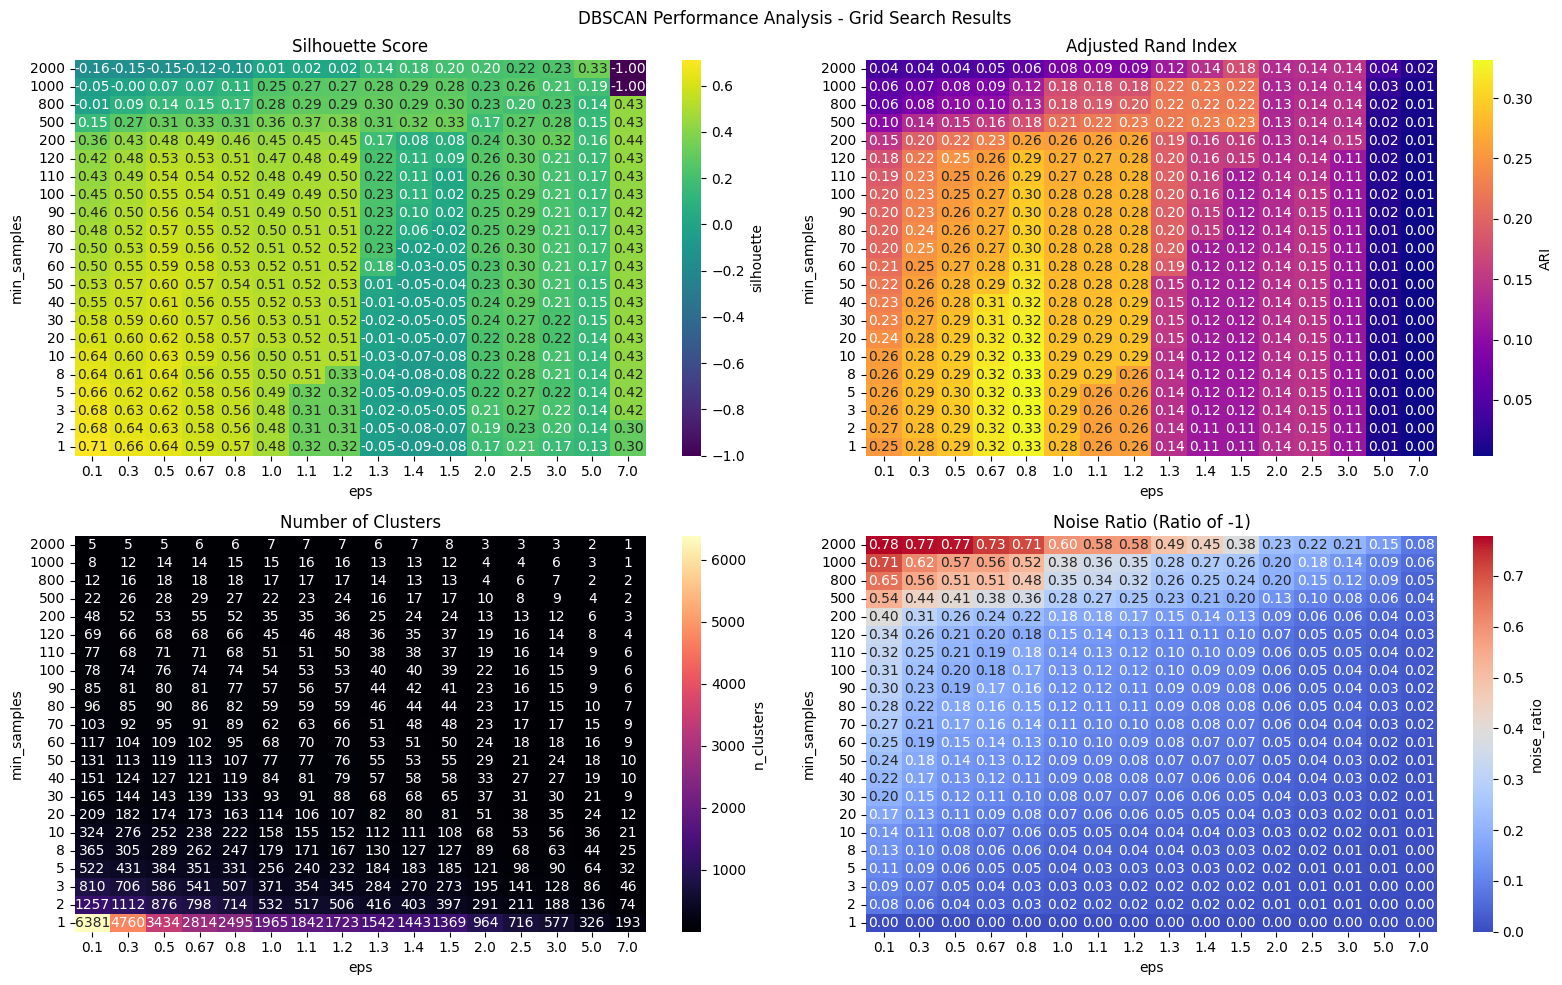

In [9]:
plot_dbscan_metrics(results)

## HEATMAP

In [10]:
def plot_label_cluster_heatmap(cluster_labels, true_labels, normalize=True):
    df = pd.DataFrame({"label": true_labels,"cluster": cluster_labels})
    table = (df.groupby("label")["cluster"].value_counts().unstack(fill_value=0))

    if normalize:
        table = table.div(table.sum(axis=1), axis=0) *100

    plt.figure(figsize=(50,10))
    sns.heatmap(table, 
                cmap="viridis", 
                cbar=True, 
                cbar_kws={"ticks": np.linspace(0, 100 if normalize else table.values.max(), 5)}, 
                vmin=0, 
                vmax=100 if normalize else table.values.max(), 
                linewidths=0.1, 
                linecolor='black', 
                fmt="", 
                annot=table.map(lambda v: f"{v:.2f}".rstrip('0').rstrip('.')) if normalize else table,
                annot_kws={"size": 10})

    plt.xlabel("Cluster")
    plt.ylabel("Label")
    plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters")

    plt.tight_layout()
    plt.show()

In [11]:
def find_index_in_dict(results, target_eps, target_min_samples):
    # Iteriamo sulla lunghezza di una delle liste (es. 'eps')
    for i in range(len(results['eps'])):
        # Verifichiamo se entrambi i parametri corrispondono all'indice i
        if (round(results['eps'][i], 2) == round(target_eps, 2) and 
            results['min_samples'][i] == target_min_samples):
            return i
    return None

Indice trovato: 191
Silhouette: 0.3814865274107457
ARI: 0.2275055210943988


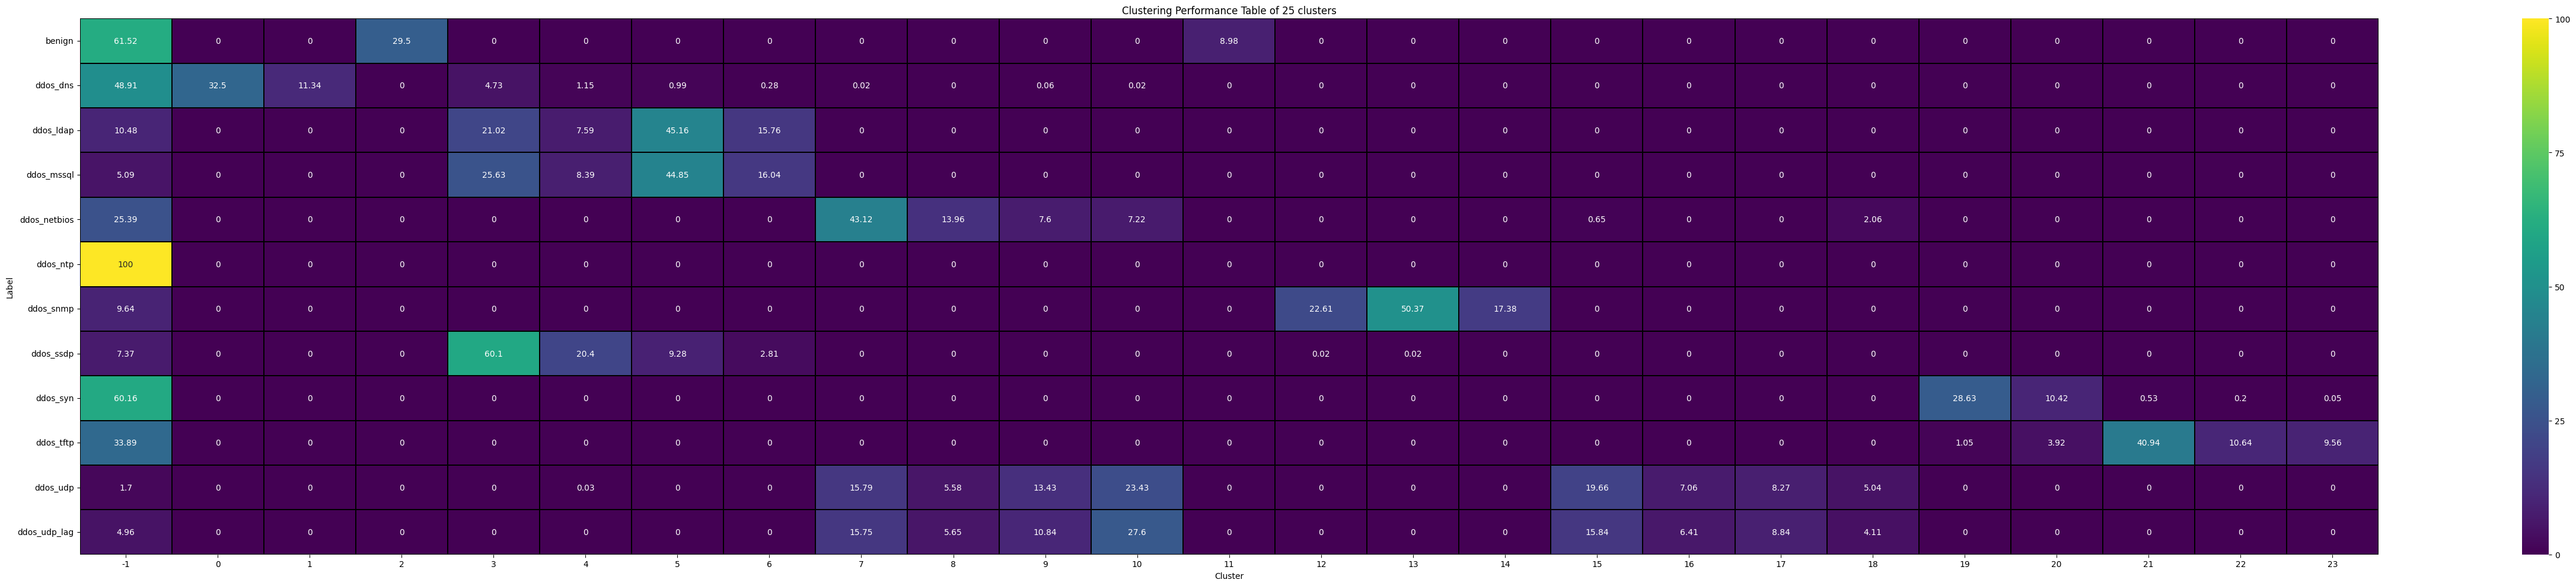

In [16]:
idx = find_index_in_dict(results, 1.2, 500)

if idx is not None:
    print(f"Indice trovato: {idx}")
    print(f"Silhouette: {results['silhouette'][idx]}")
    print(f"ARI: {results['ARI'][idx]}")
else:
    print("Combinazione non trovata.")

plot_label_cluster_heatmap(results["cluster_labels"][idx],Y,True) # Y is the true labels

Indice trovato: 60
Silhouette: 0.5432227660283672
ARI: 0.2500209641658001


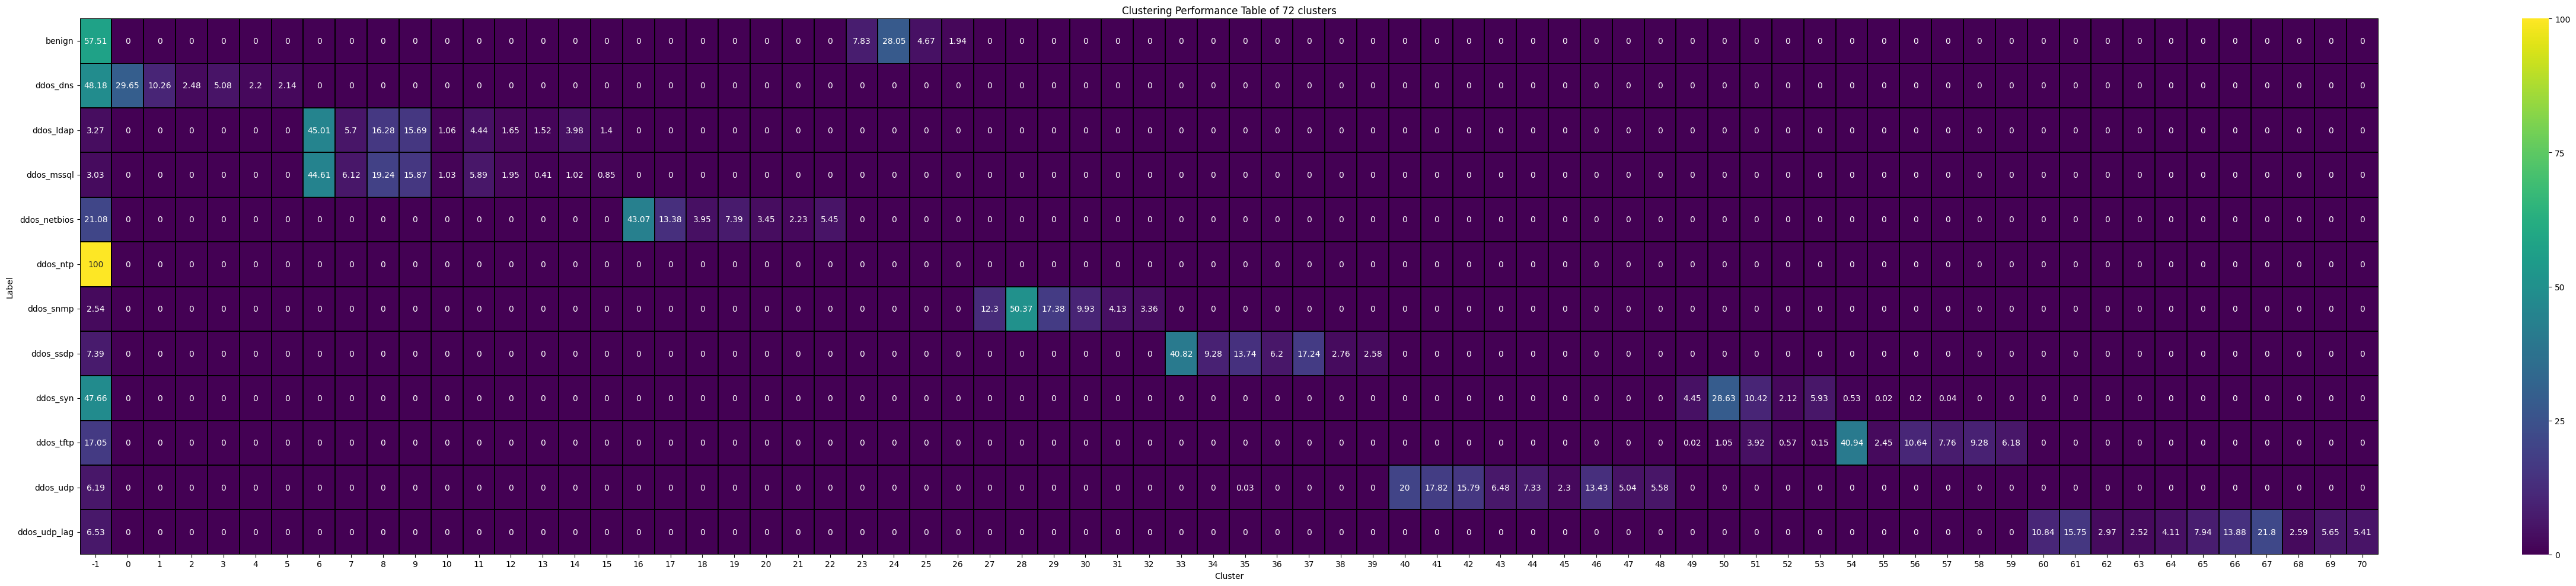

In [17]:
idx = find_index_in_dict(results, 0.5, 110)

if idx is not None:
    print(f"Indice trovato: {idx}")
    print(f"Silhouette: {results['silhouette'][idx]}")
    print(f"ARI: {results['ARI'][idx]}")
else:
    print("Combinazione non trovata.")

plot_label_cluster_heatmap(results["cluster_labels"][idx],Y,True) # Y is the true labels

Indice trovato: 257
Silhouette: 0.2886535722900333
ARI: 0.22545879448051312


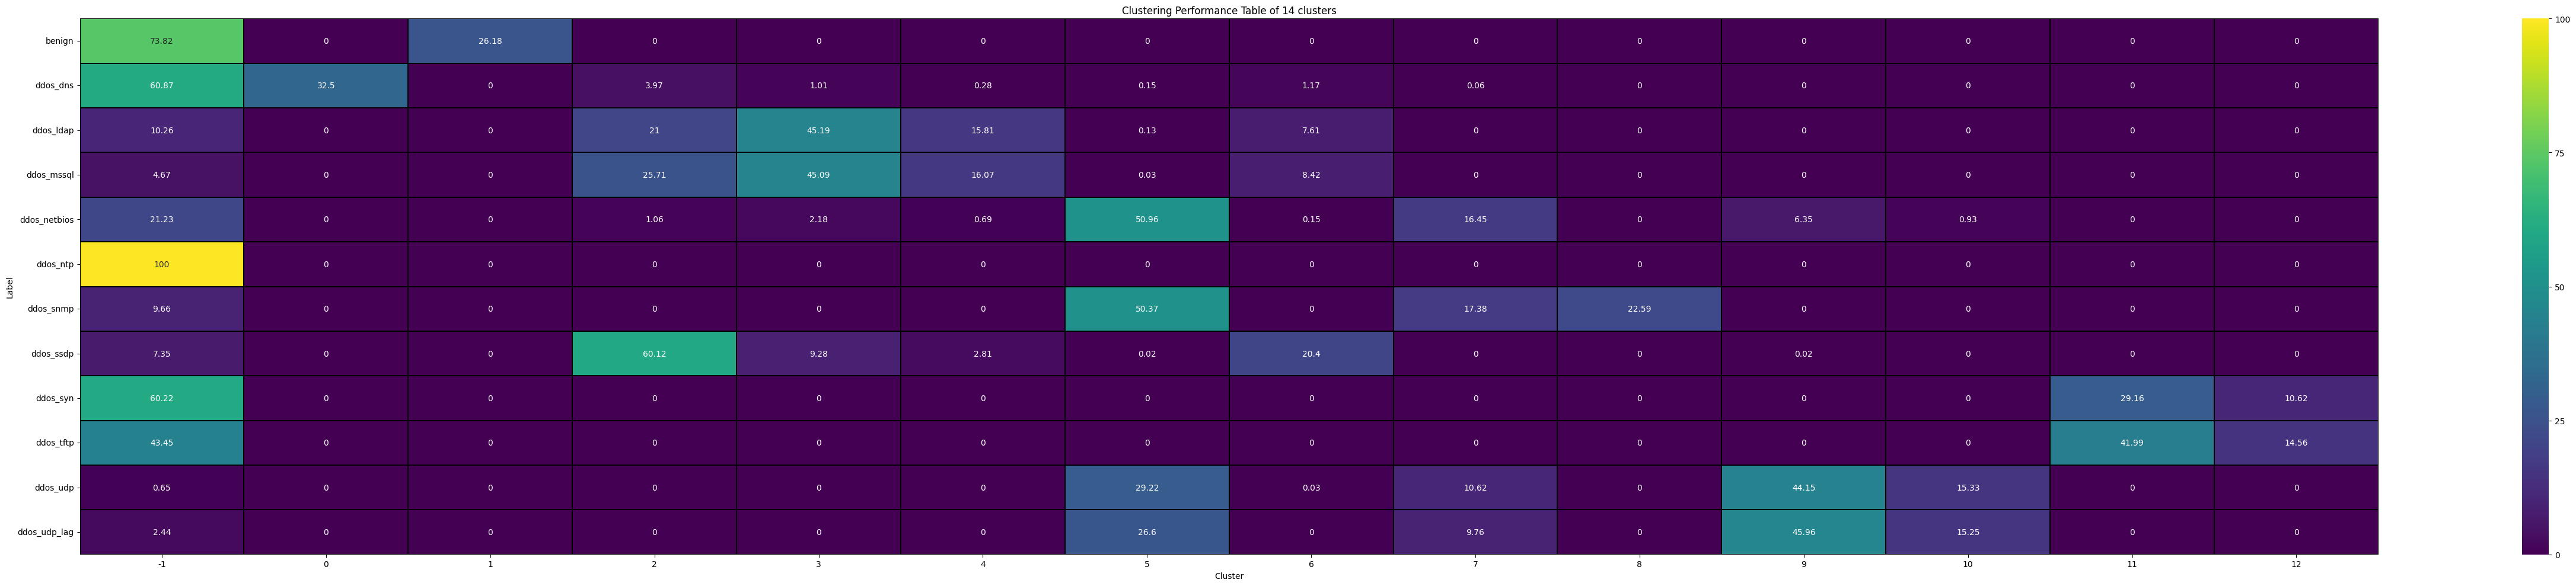

In [18]:
idx = find_index_in_dict(results, 1.4, 1000)

if idx is not None:
    print(f"Indice trovato: {idx}")
    print(f"Silhouette: {results['silhouette'][idx]}")
    print(f"ARI: {results['ARI'][idx]}")
else:
    print("Combinazione non trovata.")

plot_label_cluster_heatmap(results["cluster_labels"][idx],Y,True) # Y is the true labels

# Why DBSCAN is not a good choice in this type of dataset?

DBSCAN has problems with this dataset because of the following list of reasons:

- High dimensionality of the dataset: DBSCAN suffer high dimensionality datasets. Euclidean distances becomes less significant and points tend to be at the same distant from themselves, making difficult to distinguish among different densities;
- Variable density: Dataset of DDoS attacks typically have classes with very different densities. DBSCAN uses global parameters that do not adapt well to clusters with variable densities;
- High noise ratio: A lot of points are not recognized as effective data but as noise by DBSCAN;
- Computational performance: With thousands of points and 79 dimensions, distance computation is a lot expensive;
- Low metrics: ARI suggests that the correlation with the real labels is poor, indicating that DBSCAN has difficulty to identify correct patterns of attack.

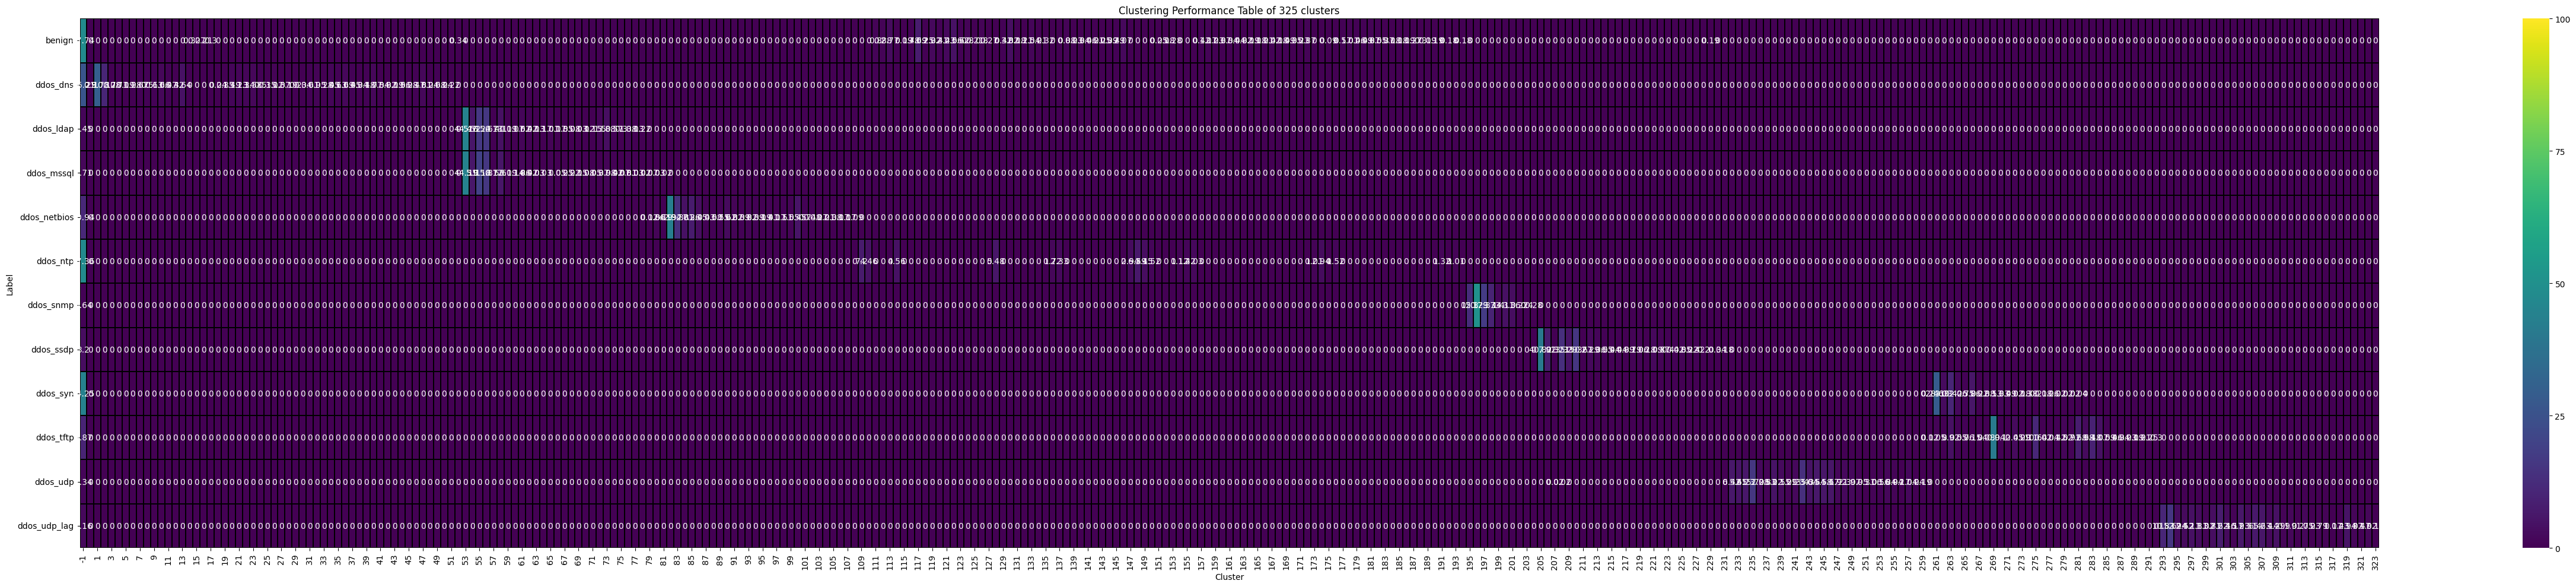

In [29]:
plot_label_cluster_heatmap(results["cluster_labels"][2-2],Y,True)

# New calculation of db + visualization

In [19]:
db=DBSCAN(eps=1.2, min_samples=500, algorithm='ball_tree',n_jobs=-1).fit(X_scaled)

In [22]:
def plot_clustering_2d(df, cl_labels, n_cluster, metric):
    pca = PCA(n_components=2)
    df_pca = pca.fit_transform(df)

    plt.figure(figsize=(14, 7))
    sns.scatterplot(x=df_pca[:,0], y=df_pca[:,1], hue=cl_labels, palette='tab10', s=30)

    plt.title(f"K-Means Clustering ({n_cluster} cluster) PCA 2D - Metric: {metric}")
    plt.xlabel("PCA 1")
    plt.ylabel("PCA 2")
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 0.5), loc='center left')
    plt.tight_layout()
    plt.show()

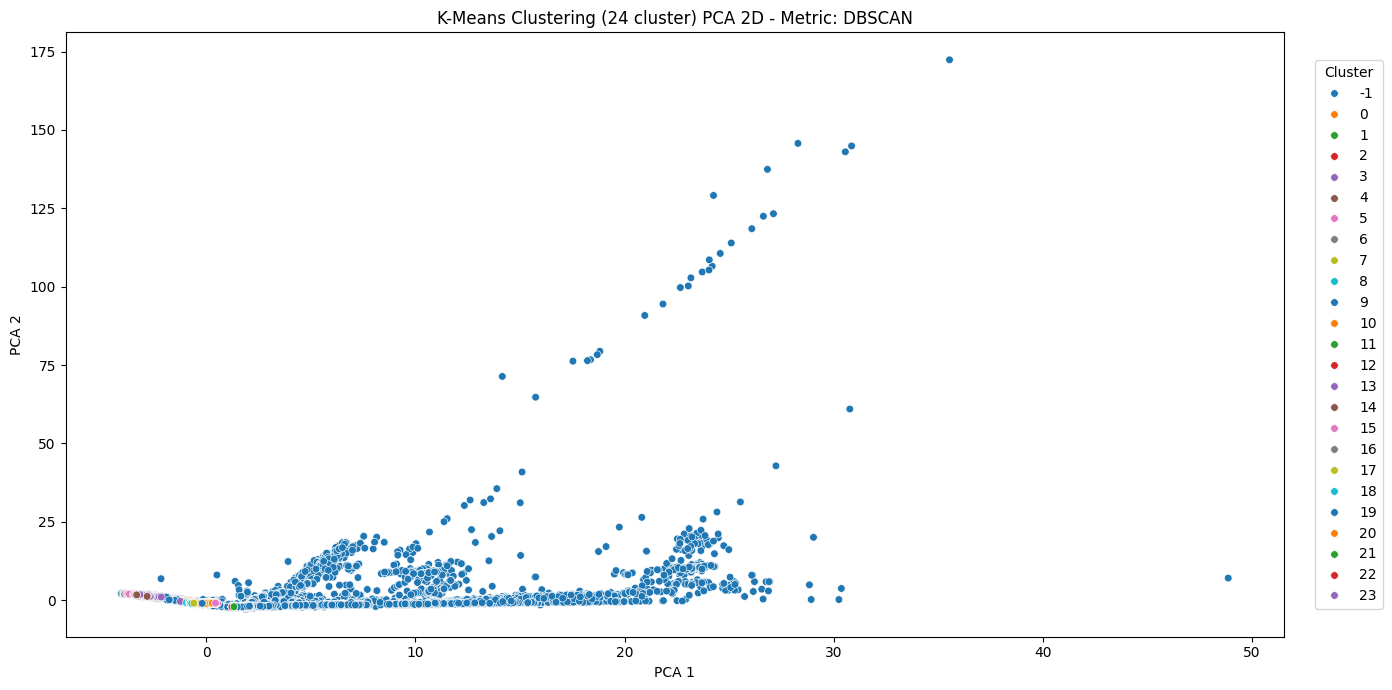

In [23]:
plot_clustering_2d(X_scaled, db.labels_, len(set(db.labels_)) - (1 if -1 in db.labels_ else 0), metric="DBSCAN")

As explained before, DBSCAN is not able to cluster samples properly. With visualization we have a clear view about this problem, as a lot of them are placed in the -1 cluster which is the outliers cluster.

As seen in K-means, the cosine method just uses vector direction to determine clusters, but in DDoS attacks, one of the most important factor is the quantity of traffic, not the direction itself, so we decided to skip the calculation for DBSCAN with it.